# Chimera v2.4 — Data Preparation

Single source of truth for training data creation. Run top-to-bottom from a clean clone.

**Pipeline overview:**

1. Download the CAMEX pancreas dataset + van Zyl aqueous humor (raw UMI counts).
2. Query Ensembl BioMart for 1:1 ortholog tables across all species.
3. Compute gene-level features: conservation prior, ESM protein embeddings,
   PCA reduction, inter-species variance, and expression statistics.
4. Construct a unified cross-species AnnData aligned by ortholog groups.
5. Precompute null expression distributions and run pre-training quality checks.
6. Save the final `.h5ad` to disk with all required fields.

| Metric | Estimate |
|---|---|
| **Runtime** | ~30 min (network-dependent; downloads cached for re-runs) |
| **Disk** | ~10 GB (raw downloads + processed outputs) |
| **Prerequisites** | `pip install -e ".[data]"` (adds `gdown` for CAMEX download) |

In [1]:
import logging
import pickle
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import torch
from scipy import stats

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")

from chimera._data_utils import (
    assemble_gin_features,
    compute_conservation_prior,
    compute_expression_stats,
    compute_esm2_interspecies_variance,
    construct_unified_adata,
    download_and_process_esm2,
    download_camex_pancreas,
    download_camex_testis,
    download_van_zyl,
    pca_esm2,
    precompute_p_null,
    query_ortholog_table,
)
from chimera._diagnostics import (
    library_size_heterogeneity_diagnostic,
    cell_type_composition_diagnostic,
)

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Resolve paths relative to this notebook
DATA_DIR = Path("../data")
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Imports OK")
print(f"Raw data dir  : {RAW_DIR.resolve()}")
print(f"Processed dir : {PROCESSED_DIR.resolve()}")

Imports OK
Raw data dir  : /Users/kemalinecik/git_nosync/master_chimera/chimera/data/raw
Processed dir : /Users/kemalinecik/git_nosync/master_chimera/chimera/data/processed


---
## 1. Download Raw Data

Load the CAMEX pancreas atlas, which contains raw UMI counts for 4--6
mammalian species (human, mouse, rat, pig, macaque, marmoset) with
cell-type and batch annotations.

On the first run, the data is downloaded from the CAMEX consortium portal
and cached locally.  Subsequent runs load from the cache.

In [2]:
adata_pancreas = download_camex_pancreas(data_dir=RAW_DIR)

print(f"CAMEX pancreas: {adata_pancreas.n_obs} cells, {adata_pancreas.n_vars} genes")
print(f"Species: {adata_pancreas.obs['species'].value_counts().to_dict()}")
print(f"Batches: {adata_pancreas.obs['batch'].nunique()}")
print(f"Cell types: {adata_pancreas.obs['cell_type'].nunique()}")

INFO: Loading cached CAMEX pancreas from ../data/raw/camex_pancreas.h5ad


CAMEX pancreas: 22104 cells, 90388 genes
Species: {'Monkey': 8483, 'Zebrafish': 5530, 'Human': 4125, 'Mouse': 3966}
Batches: 5
Cell types: 9


In [3]:
# Download van Zyl aqueous humor 5-species dataset (Task 1.2)
# Source: SATURN server (http://snap.stanford.edu/saturn/data/ah_atlas_export.tar.gz)
# Species: human, cynomolgus macaque, rhesus macaque, pig, mouse

adata_vanzyl = download_van_zyl(data_dir=RAW_DIR)

print(f"\nvan Zyl aqueous humor: {adata_vanzyl.n_obs} cells, {adata_vanzyl.n_vars} genes")
print(f"Species ({adata_vanzyl.obs['species'].nunique()}):")
for sp, cnt in adata_vanzyl.obs["species"].value_counts().items():
    n_batches = adata_vanzyl.obs.loc[adata_vanzyl.obs["species"] == sp, "batch"].nunique()
    print(f"  {sp:>25s}: {cnt:>6d} cells, {n_batches} batches")

# Validate: each batch maps to exactly one species (Task 7.2 requirement)
for b in adata_vanzyl.obs["batch"].cat.categories:
    n_sp = adata_vanzyl.obs.loc[adata_vanzyl.obs["batch"] == b, "species"].nunique()
    assert n_sp == 1, f"Batch '{b}' spans {n_sp} species!"
print("\nBatch-species constraint: PASS (each batch → one species)")

INFO: Loading cached van Zyl aqueous humor from ../data/raw/van_zyl_aqueous_humor.h5ad



van Zyl aqueous humor: 50112 cells, 256 genes
Species (5):
                      human:  24023 cells, 1 batches
        macaca_fascicularis:   9155 cells, 1 batches
                        pig:   6709 cells, 1 batches
             macaca_mulatta:   5158 cells, 1 batches
                      mouse:   5067 cells, 1 batches

Batch-species constraint: PASS (each batch → one species)


---
## 2. Ortholog Mapping and Conservation Prior

Retrieve 1:1 ortholog groups across all species present in the dataset via
Ensembl BioMart. The ortholog table maps each species' gene IDs to a common
ortholog group ID and records percent identity for each non-reference species
relative to human.

In [4]:
species_list = sorted(adata_pancreas.obs["species"].unique().tolist())
print(f"Species in dataset: {species_list}")

# Comprehensive mapping from common names to Ensembl identifiers
# Covers all 11 CAMEX testis species + van Zyl species
ENSEMBL_SPECIES = {
    "human": "hsapiens", "homo sapiens": "hsapiens",
    "mouse": "mmusculus", "mus musculus": "mmusculus",
    "macaque": "mmulatta", "rhesus macaque": "mmulatta",
    "monkey": "mmulatta",
    "cynomolgus macaque": "mfascicularis",
    "pig": "sscrofa", "sus scrofa": "sscrofa",
    "zebrafish": "drerio",
    "rat": "rnorvegicus",
    "chimpanzee": "ptroglodytes", "chimp": "ptroglodytes",
    "gorilla": "ggorilla",
    "bonobo": "ppaniscus",
    "gibbon": "nleucogenys",
    "marmoset": "cjacchus",
    "opossum": "mdomestica",
    "platypus": "oanatinus",
    "chicken": "ggallus",
}

ensembl_names = {}  # common → ensembl (for later use in per-species split)
ensembl_species = []
for sp in species_list:
    sp_lower = sp.lower().strip()
    if sp_lower in ENSEMBL_SPECIES:
        ens = ENSEMBL_SPECIES[sp_lower]
    else:
        logging.warning("No Ensembl mapping for '%s' — using as-is", sp)
        ens = sp_lower
    ensembl_names[sp] = ens
    ensembl_species.append(ens)

print(f"Ensembl species: {ensembl_species}")

ortholog_table = query_ortholog_table(
    species_list=ensembl_species,
    reference_species="hsapiens",
    cache_dir=PROCESSED_DIR,
)
print(f"\n1:1 ortholog groups: {len(ortholog_table)}")
print(f"Mean identity: {ortholog_table['mean_identity'].mean():.1f}%")
print(f"Median identity: {ortholog_table['mean_identity'].median():.1f}%")

# Log intersection size for Caveat 25 (ascertainment bias)
print(f"\nNote (Caveat 25): 1:1 ortholog restriction enriches for slowly evolving,")
print(f"functionally constrained genes. Intersection size = {len(ortholog_table)} genes.")

INFO: Loading cached ortholog table from ../data/processed/ortholog_table.csv


Species in dataset: ['Human', 'Monkey', 'Mouse', 'Zebrafish']
Ensembl species: ['hsapiens', 'mmulatta', 'mmusculus', 'drerio']



1:1 ortholog groups: 8879
Mean identity: 80.0%
Median identity: 81.0%

Note (Caveat 25): 1:1 ortholog restriction enriches for slowly evolving,
functionally constrained genes. Intersection size = 8879 genes.


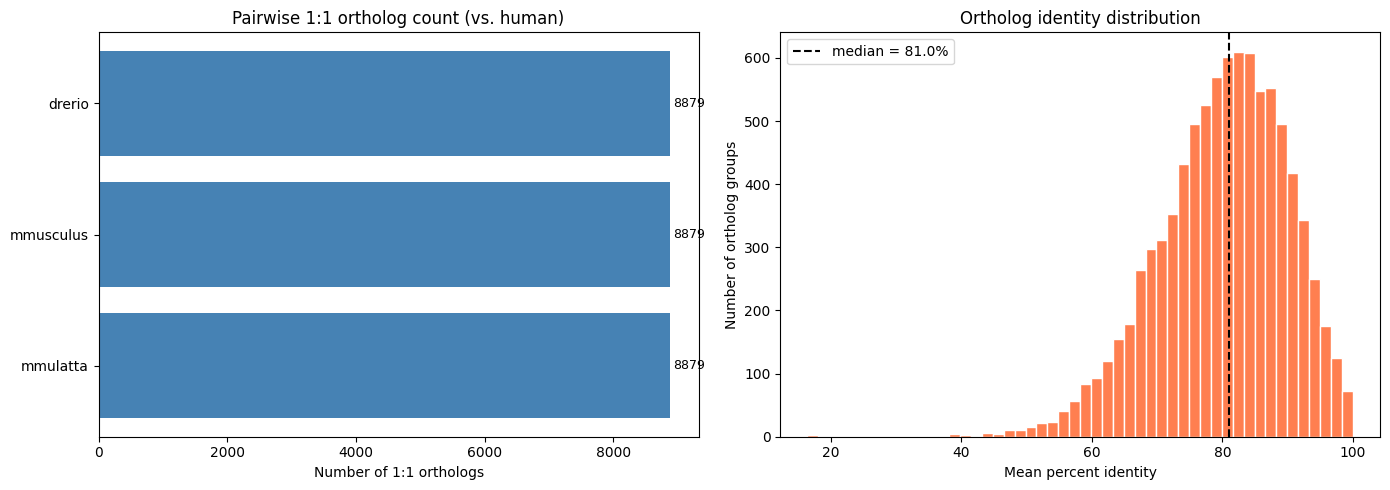

In [5]:
# --- Ortholog QC: pairwise ortholog counts and identity distributions ---

non_ref_species = [s for s in ensembl_species if s != "hsapiens"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Number of 1:1 orthologs contributed by each pairwise comparison
pair_counts = {}
for sp in non_ref_species:
    id_col = f"{sp}_gene_id"
    if id_col in ortholog_table.columns:
        pair_counts[sp] = ortholog_table[id_col].notna().sum()

axes[0].barh(list(pair_counts.keys()), list(pair_counts.values()), color="steelblue")
axes[0].set_xlabel("Number of 1:1 orthologs")
axes[0].set_title("Pairwise 1:1 ortholog count (vs. human)")
for i, (sp, cnt) in enumerate(pair_counts.items()):
    axes[0].text(cnt + 50, i, str(cnt), va="center", fontsize=9)

# (b) Distribution of mean percent identity across ortholog groups
axes[1].hist(
    ortholog_table["mean_identity"].dropna(),
    bins=50,
    color="coral",
    edgecolor="white",
)
axes[1].axvline(
    ortholog_table["mean_identity"].median(),
    color="black",
    linestyle="--",
    label=f"median = {ortholog_table['mean_identity'].median():.1f}%",
)
axes[1].set_xlabel("Mean percent identity")
axes[1].set_ylabel("Number of ortholog groups")
axes[1].set_title("Ortholog identity distribution")
axes[1].legend()

fig.tight_layout()
plt.show()

---
## 3. Gene Features

Chimera v2.4 uses a Gene Interaction Network (GIN) that consumes per-gene
feature vectors to learn the shared/residual mixing coefficient (alpha).
The feature vector has ~72 dimensions:

| Feature block | Dims | Source |
|---|---|---|
| ESM-2 PCA | 64 | SATURN ESM-2 3B protein embeddings, PCA-reduced |
| ESM-2 inter-species variance | 1 | Mean pairwise cosine distance across species |
| Mean identity | 1 | From ortholog table |
| Expression stats | 3 | log mean, log variance, fraction non-zero |
| Identity spread | 3 | std / max / min of per-species pairwise identity |

Conservation prior shape: torch.Size([8879])
  range: [0.164, 0.950]
  mean:  0.799


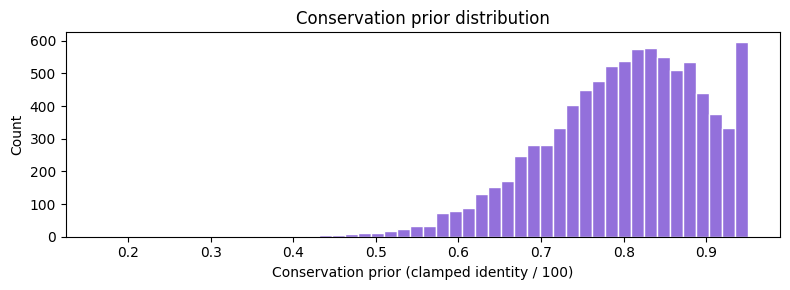

In [6]:
# 3a. Conservation prior from ortholog percent identity
conservation_prior = compute_conservation_prior(ortholog_table)

print(f"Conservation prior shape: {conservation_prior.shape}")
print(f"  range: [{conservation_prior.min().item():.3f}, {conservation_prior.max().item():.3f}]")
print(f"  mean:  {conservation_prior.mean().item():.3f}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(conservation_prior.numpy(), bins=50, color="mediumpurple", edgecolor="white")
ax.set_xlabel("Conservation prior (clamped identity / 100)")
ax.set_ylabel("Count")
ax.set_title("Conservation prior distribution")
fig.tight_layout()
plt.show()

In [7]:
# 3b. ESM-2 protein embeddings: download, consensus, PCA, inter-species variance

# download_and_process_esm2 returns:
#   consensus_emb        -- (G, 5120) consensus across species (mean over species)
#   per_species_emb      -- {sp: (G, 5120)} per-species embedding matrices; rows for
#                           unmatched ortholog groups are all-zero and treated as
#                           missing by compute_esm2_interspecies_variance.
consensus_emb, per_species_emb = download_and_process_esm2(
    ortholog_table,
    species_list=ensembl_species,
    saturn_data_dir=RAW_DIR / "saturn_esm2",
)
print(f"Consensus ESM-2 embeddings: {consensus_emb.shape}")

# PCA: 5120 -> 64 dimensions.
esm2_pca = pca_esm2(consensus_emb, n_components=64)
print(f"ESM-2 PCA: {esm2_pca.shape}")

# Inter-species variance: mean pairwise cosine distance per ortholog group.
# Uses masks internally so unmatched rows do not contaminate the distance.
esm2_interspecies_var = compute_esm2_interspecies_variance(per_species_emb)
print(f"ESM-2 inter-species variance: {esm2_interspecies_var.shape}")
print(f"  mean cosine dist: {esm2_interspecies_var.mean():.4f}")
print(f"  non-zero genes  : {int((esm2_interspecies_var > 0).sum())} / {len(esm2_interspecies_var)}")

INFO: Loaded embeddings for hsapiens from human_embedding.torch (19790 genes, dim=5120)


INFO:   hsapiens: matched 8764 / 8879 ortholog genes


INFO: Loaded embeddings for mmulatta from macaca_mulatta_embedding.torch (16775 genes, dim=5120)


INFO:   mmulatta: matched 8708 / 8879 ortholog genes


INFO: Loaded embeddings for mmusculus from mouse_embedding.torch (22324 genes, dim=5120)


INFO:   mmusculus: matched 8754 / 8879 ortholog genes


... (2 outputs left out)

Consensus ESM-2 embeddings: (8879, 5120)


INFO: PCA ESM-2: 5120 -> 64, explained variance=0.580


ESM-2 PCA: (8879, 64)


ESM-2 inter-species variance: (8879,)
  mean cosine dist: 0.0758
  non-zero genes  : 8878 / 8879


In [8]:
# 3c. Expression stats and GIN feature assembly
#
# Expression statistics require the unified AnnData (computed in Section 4).
# We store the partial features here and complete assembly after unification.

print("Expression stats and full GIN feature assembly deferred to Section 4.")
print(f"Partial features ready:")
print(f"  esm2_pca             : {esm2_pca.shape}")
print(f"  esm2_interspecies_var: {esm2_interspecies_var.shape}")
print(f"  conservation_prior   : {conservation_prior.shape}")

Expression stats and full GIN feature assembly deferred to Section 4.
Partial features ready:
  esm2_pca             : (8879, 64)
  esm2_interspecies_var: (8879,)
  conservation_prior   : torch.Size([8879])


---
## 4. Unified AnnData Construction

Each species' expression matrix uses its own gene namespace.  Here we:

1. Split the raw data into per-species AnnData objects.
2. Map each species' genes to ortholog group IDs using the ortholog table.
3. Concatenate into a single unified AnnData where columns = ortholog groups.
4. Compute expression statistics on the unified data.
5. Assemble and attach the full GIN feature matrix.

In [9]:
# 4a. Split raw data into per-species AnnDatas
per_species_adatas = {}
for sp_common in species_list:
    sp_mask = adata_pancreas.obs["species"] == sp_common
    sp_adata = adata_pancreas[sp_mask].copy()
    # Use the Ensembl species name as the key for ortholog table matching
    ensembl_name = ensembl_names[sp_common]
    per_species_adatas[ensembl_name] = sp_adata
    print(f"  {sp_common:>10s} ({ensembl_name}): {sp_adata.n_obs:>6d} cells, {sp_adata.n_vars:>6d} genes")

print(f"\nTotal species: {len(per_species_adatas)}")

       Human (hsapiens):   4125 cells,  90388 genes
      Monkey (mmulatta):   8483 cells,  90388 genes
       Mouse (mmusculus):   3966 cells,  90388 genes


   Zebrafish (drerio):   5530 cells,  90388 genes

Total species: 4


In [10]:
# 4b. Construct unified AnnData aligned by ortholog groups
#
# We pass placeholder gene features here; the real features are attached
# after computing expression statistics on the unified data.

G = len(ortholog_table)
placeholder_features = np.zeros((G, 72), dtype=np.float32)

unified_adata = construct_unified_adata(
    per_species_adatas=per_species_adatas,
    ortholog_table=ortholog_table,
    gene_features=placeholder_features,
    conservation_prior=conservation_prior,
)

print(f"Unified AnnData: {unified_adata.n_obs} cells x {unified_adata.n_vars} genes (ortholog groups)")
print(f"Species: {unified_adata.obs['species'].value_counts().to_dict()}")
print(f"Batches: {unified_adata.obs['batch'].nunique()}")

INFO: Mapping hsapiens via hsapiens_gene_name: 8739 / 8879 ortholog genes matched


INFO: Mapping mmulatta via mmulatta_gene_name: 8584 / 8879 ortholog genes matched


INFO: Mapping mmusculus via mmusculus_gene_name: 8571 / 8879 ortholog genes matched


INFO: Mapping drerio via drerio_gene_name: 6130 / 8879 ortholog genes matched


Unified AnnData: 22104 cells x 8879 genes (ortholog groups)
Species: {'Monkey': 8483, 'Zebrafish': 5530, 'Human': 4125, 'Mouse': 3966}
Batches: 5


In [11]:
# 4c. Compute expression statistics on unified data and assemble GIN features

expression_stats = compute_expression_stats(unified_adata)
print("Expression statistics:")
for key, arr in expression_stats.items():
    print(f"  {key:>15s}: shape={arr.shape}, mean={arr.mean():.4f}, std={arr.std():.4f}")

gene_features, gin_scaler = assemble_gin_features(
    esm2_pca=esm2_pca,
    esm2_interspecies_var=esm2_interspecies_var,
    ortholog_table=ortholog_table,
    expression_stats=expression_stats,
)
print(f"\nGIN features: {gene_features.shape} (StandardScaled)")
print(f"  per-dim mean ~ {gene_features.mean(axis=0).mean():.6f} (should be ~0)")
print(f"  per-dim std  ~ {gene_features.std(axis=0).mean():.6f} (should be ~1)")

# Replace placeholder features in the unified AnnData
unified_adata.varm["gene_features"] = gene_features

INFO: GIN features: shape=(8879, 72)


Expression statistics:
    log_mean_expr: shape=(8879,), mean=0.1522, std=0.2521
     log_expr_var: shape=(8879,), mean=0.3280, std=0.6572
     frac_nonzero: shape=(8879,), mean=0.0931, std=0.1151

GIN features: (8879, 72) (StandardScaled)
  per-dim mean ~ 0.000000 (should be ~0)
  per-dim std  ~ 1.000000 (should be ~1)


---
## 5. p_null and Quality Checks

Before training, we:

1. Precompute the **null expression distribution** (Laplace-smoothed gene
   proportions per species) used by the NB reconstruction loss.
2. Run **library-size heterogeneity** diagnostics to decide whether to use
   observed or learned library sizes.
3. Run **cell-type composition** diagnostics to flag species with dominant
   cell types that could bias integration.
4. Run the **pre-training conservation signal** check to confirm the
   conservation prior correlates with expression pattern similarity.

p_null shape: (4, 8879)  (K=4 species x G=8879 genes)
Row sums (should be ~1): [0.99999995 1.         1.         1.        ]


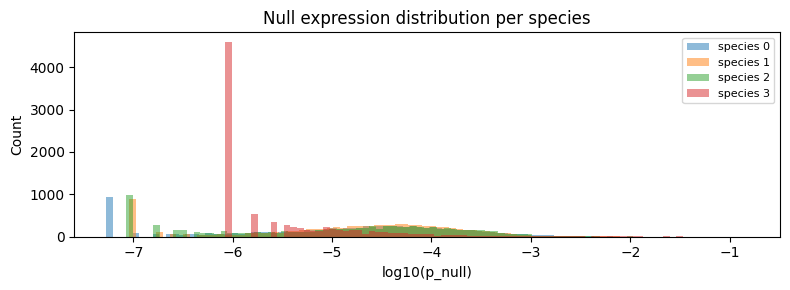

In [12]:
# 5a. Precompute p_null
p_null = precompute_p_null(unified_adata)

n_species_null = p_null.shape[0]
print(f"p_null shape: {p_null.shape}  (K={n_species_null} species x G={p_null.shape[1]} genes)")
print(f"Row sums (should be ~1): {p_null.sum(axis=1)}")

fig, ax = plt.subplots(figsize=(8, 3))
for s_idx in range(n_species_null):
    ax.hist(
        np.log10(p_null[s_idx] + 1e-12),
        bins=80,
        alpha=0.5,
        label=f"species {s_idx}",
    )
ax.set_xlabel("log10(p_null)")
ax.set_ylabel("Count")
ax.set_title("Null expression distribution per species")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [13]:
# 5b. Library-size heterogeneity diagnostic
from chimera._diagnostics import library_size_heterogeneity_diagnostic

lib_diag = library_size_heterogeneity_diagnostic(unified_adata)

print(f"Library size ratio: {lib_diag['max_min_ratio']:.2f}x")
print(f"Recommendation: {lib_diag['recommendation']}")
print(f"Use observed lib size: {lib_diag['use_observed_lib_size']}")
print(f"Details: {lib_diag['details']}")
print(f"\nPer-species median library sizes:")
for sp_name, med_lib in sorted(lib_diag["per_species_median_lib"].items()):
    print(f"  {sp_name:>10s}: {med_lib:,.0f}")

INFO: Library size diagnostic: Library-size ratio 17.60x is very high (>5x). Using learned library sizes, but extreme heterogeneity may indicate data quality issues or protocol differences. Consider investigating further.


Library size ratio: 17.60x
Recommendation: learned_with_warning
Use observed lib size: False
Details: Library-size ratio 17.60x is very high (>5x). Using learned library sizes, but extreme heterogeneity may indicate data quality issues or protocol differences. Consider investigating further.

Per-species median library sizes:
       Human: 3,414
      Monkey: 1,140
       Mouse: 2,760
   Zebrafish: 194


In [14]:
# 5c. Cell-type composition diagnostic

comp_diag = cell_type_composition_diagnostic(unified_adata)

print(f"Flagged species: {comp_diag['flagged_species']}")
print(f"Details: {comp_diag['details']}")

INFO: Composition diagnostic: Species with dominant cell type (>80%): Zebrafish (Hepatocytes: 95.6%). This may bias integration -- consider whether these species have genuine biological composition differences or sampling bias.


Flagged species: ['Zebrafish']
Details: Species with dominant cell type (>80%): Zebrafish (Hepatocytes: 95.6%). This may bias integration -- consider whether these species have genuine biological composition differences or sampling bias.


In [15]:
# 5d. Pre-training conservation signal check (Task 9.9 preview)
#
# Before investing in full model training, verify that conservation features
# have predictive power for expression similarity in this dataset.

species_vals = unified_adata.obs["species"].values
unique_sp = np.unique(species_vals)
X = unified_adata.X
if hasattr(X, "toarray"):
    X_dense = X.toarray()
else:
    X_dense = np.asarray(X)

# Per-gene cross-species expression similarity (1 - CV of species means)
sp_means = np.stack([X_dense[species_vals == sp].mean(axis=0) for sp in unique_sp])  # (K, G)
gene_sim = np.array([
    1.0 - sp_means[:, g].std() / (sp_means[:, g].mean() + 1e-8)
    for g in range(unified_adata.n_vars)
])

# Conservation prior
prior_vals = unified_adata.var["conservation_prior"].values

r_global, p_global = stats.spearmanr(prior_vals, gene_sim)
print(f"Conservation signal check:")
print(f"  Spearman r = {r_global:.4f}  (p = {p_global:.2e})")
print(f"  Decision: {'PROCEED — conservation predicts expression similarity' if r_global > 0.2 else 'INVESTIGATE — weak conservation signal'}")
print(f"\n  Interpretation:")
print(f"    r > 0.2 : conservation is informative, proceed with full feature vector")
print(f"    r ~ 0   : conservation is uninformative, consider ESM-2-only features")

Conservation signal check:
  Spearman r = 0.1223  (p = 5.95e-31)
  Decision: INVESTIGATE — weak conservation signal

  Interpretation:
    r > 0.2 : conservation is informative, proceed with full feature vector
    r ~ 0   : conservation is uninformative, consider ESM-2-only features


---
## 6. Save and Verify

Write the unified AnnData to disk and verify that all required fields are
present. Run a smoke test with `ChimeraModel.setup_anndata()` to confirm
the output is training-ready.

In [16]:
# Save p_null alongside unified AnnData
unified_adata.uns["p_null"] = p_null

# Save GIN scaler for inference
with open(PROCESSED_DIR / "gin_scaler.pkl", "wb") as f:
    pickle.dump(gin_scaler, f)

output_path = PROCESSED_DIR / "camex_pancreas_unified.h5ad"
unified_adata.write_h5ad(output_path)
print(f"Saved unified AnnData to {output_path}")
print(f"File size: {output_path.stat().st_size / 1e6:.1f} MB")

# --- Assertions: verify all required fields ---
assert "species" in unified_adata.obs.columns, "Missing obs['species']"
assert "batch" in unified_adata.obs.columns, "Missing obs['batch']"
assert "gene_features" in unified_adata.varm, "Missing varm['gene_features']"
assert "conservation_prior" in unified_adata.var.columns, "Missing var['conservation_prior']"
assert "p_null" in unified_adata.uns, "Missing uns['p_null']"

print("\nField verification:")
print(f"  obs['species']             : {unified_adata.obs['species'].nunique()} unique")
print(f"  obs['batch']               : {unified_adata.obs['batch'].nunique()} unique")
print(f"  varm['gene_features']      : {unified_adata.varm['gene_features'].shape}")
print(f"  var['conservation_prior']  : {unified_adata.var['conservation_prior'].shape}")
print(f"  uns['p_null']              : {unified_adata.uns['p_null'].shape}")
print(f"  .X shape                   : {unified_adata.X.shape}")

# --- Smoke test: ChimeraModel.setup_anndata + construction ---
from chimera import ChimeraModel

adata_test = ad.read_h5ad(output_path)
ChimeraModel.setup_anndata(adata_test, species_key="species", batch_key="batch")
model = ChimeraModel(adata_test)
alpha = model.get_alpha()
print(f"\nChimeraModel smoke test:")
print(f"  Alpha shape: {alpha.shape}")
print(f"  Alpha range: [{alpha.min():.4f}, {alpha.max():.4f}]")
print(f"  Alpha mean:  {alpha.mean():.4f}")

print("\nAll assertions passed. Data preparation complete.")

Saved unified AnnData to ../data/processed/camex_pancreas_unified.h5ad
File size: 153.6 MB

Field verification:
  obs['species']             : 4 unique
  obs['batch']               : 5 unique
  varm['gene_features']      : (8879, 72)
  var['conservation_prior']  : (8879,)
  uns['p_null']              : (4, 8879)
  .X shape                   : (22104, 8879)



ChimeraModel smoke test:
  Alpha shape: (8879,)
  Alpha range: [0.1638, 0.9500]
  Alpha mean:  0.7994

All assertions passed. Data preparation complete.


---
## 7. 2-species subsets

Downstream training entry points in `chimera/training/workflow.md` often
operate on 2-species subsets for fast iteration and ablation sweeps. We
build the three canonical Human+X pairs here so that a fresh run of this
notebook produces every `.h5ad` that downstream scripts reference.

| Subset | Path | Used by |
|---|---|---|
| Human + Monkey | `data/processed/camex_human_monkey.h5ad` | `run_experiment.py --config A` (default/ablation baseline) |
| Human + Mouse  | `data/processed/camex_human_mouse.h5ad`  | `--adv-weight 200 --free-bits 1.0` (4-sp recipe calibrated on a 2-sp proxy) |
| Human + Zebrafish | `data/processed/camex_human_zebrafish.h5ad` | cross-dataset sweep (XDS) |

Each subset is built via `chimera/training/build_subset.py` so the output
is identical to running `python training/build_subset.py --species ...`
from the command line. For every subset we:

1. Filter cells to the selected species.
2. Drop genes expressed in fewer than 3 cells after subsetting (conservative
   default — prevents carrying genes that are only informative in the
   dropped species).
3. Recompute `p_null` on the subset (it is species- and gene-indexed).
4. Carry over the 72-D `gene_features` matrix from the full-dataset
   `StandardScaler` unchanged (see `build_subset.py` for rationale).
5. Write a matching `_config.json` with cell counts and summary stats.

In [17]:
# --- Import build_subset.py from the sibling training/ directory. ---
# training/ is a flat script directory (no __init__.py), so we add it to
# sys.path and import the function directly. This matches how build_subset.py
# itself bootstraps its own imports when run as a script.
import sys
_TRAINING_DIR = (Path.cwd() / ".." / "training").resolve()
if str(_TRAINING_DIR) not in sys.path:
    sys.path.insert(0, str(_TRAINING_DIR))

from build_subset import build_subset  # noqa: E402

# The three Human + X pairs referenced by chimera/training/workflow.md.
SUBSET_SPECS = [
    ("Human", "Monkey"),
    ("Human", "Mouse"),
    ("Human", "Zebrafish"),
]

subset_paths = []
for species_pair in SUBSET_SPECS:
    tag = "_".join(s.lower() for s in species_pair)
    dest = PROCESSED_DIR / f"camex_{tag}.h5ad"
    print(f"\n=== Building subset {species_pair} -> {dest.name} ===")
    build_subset(
        source_path=output_path,         # unified h5ad written in Section 6
        species=species_pair,
        dest_path=dest,
        drop_empty_genes=True,
        min_cells_per_gene=3,
    )
    subset_paths.append(dest)

# --- Verification: re-open each subset and smoke-test with ChimeraModel. ---
print("\nSubset summary:")
for p in subset_paths:
    sub = ad.read_h5ad(p)
    size_mb = p.stat().st_size / 1e6
    species_counts = sub.obs["species"].value_counts().to_dict()
    print(
        f"  {p.name:<38s} "
        f"cells={sub.n_obs:>6d}  genes={sub.n_vars:>5d}  "
        f"size={size_mb:>5.1f} MB  species={species_counts}"
    )
    # Each subset must survive ChimeraModel.setup_anndata so it is training-ready.
    ChimeraModel.setup_anndata(sub, species_key="species", batch_key="batch")
    m = ChimeraModel(sub)
    alpha = m.get_alpha()
    print(
        f"    ChimeraModel smoke test: alpha shape={alpha.shape}, "
        f"range=[{alpha.min():.3f}, {alpha.max():.3f}], mean={alpha.mean():.3f}"
    )

print("\nAll subsets built and verified.")

INFO: Loading ../data/processed/camex_pancreas_unified.h5ad


INFO: Selecting species: ('Human', 'Monkey')


INFO: After species filter: 12608 cells, 8879 genes. Species counts: {'Monkey': 8483, 'Human': 4125}. Batches: {'CS173': 4427, 'CS170': 4125, 'CS172': 4056}



=== Building subset ('Human', 'Monkey') -> camex_human_monkey.h5ad ===


INFO: Dropping 449 / 8879 genes expressed in fewer than 3 cells after species filter.


INFO: Recomputing p_null on the subset...


... (20 outputs left out)

INFO: Wrote metadata to ../data/processed/camex_human_zebrafish_config.json



Subset summary:
  camex_human_monkey.h5ad                cells= 12608  genes= 8430  size=107.4 MB  species={'Monkey': 8483, 'Human': 4125}
    ChimeraModel smoke test: alpha shape=(8430,), range=[0.164, 0.950], mean=0.800


  camex_human_mouse.h5ad                 cells=  8091  genes= 8257  size= 95.5 MB  species={'Human': 4125, 'Mouse': 3966}
    ChimeraModel smoke test: alpha shape=(8257,), range=[0.164, 0.950], mean=0.801
  camex_human_zebrafish.h5ad             cells=  9655  genes= 7998  size= 58.8 MB  species={'Zebrafish': 5530, 'Human': 4125}


    ChimeraModel smoke test: alpha shape=(7998,), range=[0.164, 0.950], mean=0.802

All subsets built and verified.


---
## 8. CAMEX testis (3-species subset) — additive dataset

> **Scope.** This section is strictly *additive*. It uses the same helpers
> and the same schema as the pancreas sections above; nothing written by
> Sections 1-7 is read, modified, or overwritten. The outputs live under
> different filenames (`camex_testis_*`) so the two datasets coexist.

### Why only 3 species?

The CAMEX testis benchmark contains **11 species** (human, chimpanzee, bonobo,
gorilla, gibbon, rhesus macaque, marmoset, mouse, opossum, platypus, chicken).
SATURN provides per-species ESM-2 protein embeddings for only **8 species**,
and the intersection with the testis panel is:

- ✅ `hsapiens` (human), `mmulatta` (rhesus macaque), `mmusculus` (mouse)
- ❌ `ptroglodytes`, `ppaniscus`, `ggorilla`, `nleucogenys`, `cjacchus`,
     `mdomestica`, `oanatinus`, `ggallus` — not in SATURN on disk

Running the full 11-species pipeline today would leave 8 of 11 species with
empty ESM-2 rows, giving a meaningless cross-species variance feature. We
therefore restrict the testis dataset to the **3 species with embeddings**.
Extending to more species later is a matter of fetching the corresponding
SATURN `.torch` files (or computing ESM-2 embeddings locally) and updating
the filter below — no structural change is needed.

### Expected outputs

| Artifact | Path |
|---|---|
| Raw cache | `data/raw/camex_testis.h5ad` |
| Ortholog table | `data/processed/ortholog_table_testis.csv` |
| Unified AnnData | `data/processed/camex_testis_unified.h5ad` |
| GIN scaler | `data/processed/gin_scaler_testis.pkl` |

### Runtime warning

First-run cost is dominated by the CAMEX gdown — several hundred MB of raw
`.h5ad` files plus the ortholog biomart query for a new species list.
`download_camex_testis` skips downloads that are already on disk (gdown
resume-mode) so subsequent runs are fast.

In [18]:
# 8.1 — Download CAMEX testis (11-species raw).
from chimera._data_utils import download_camex_testis

adata_testis_raw = download_camex_testis(data_dir=RAW_DIR)
print(f"CAMEX testis (raw): {adata_testis_raw.n_obs} cells, {adata_testis_raw.n_vars} genes")
print(f"Species: {adata_testis_raw.obs['species'].value_counts().to_dict()}")
print(f"Batches: {adata_testis_raw.obs['batch'].nunique()}")
print(f"Cell types: {adata_testis_raw.obs['cell_type'].nunique()}")

INFO: Loading cached CAMEX testis from ../data/raw/camex_testis.h5ad


CAMEX testis (raw): 95967 cells, 53088 genes
Species: {'Human': 15980, 'Chimpanzee': 12318, 'Bonobo': 9873, 'Opossum': 9661, 'Chicken': 8413, 'Macaque': 7613, 'Gorilla': 7141, 'Platypus': 6751, 'Gibbon': 6572, 'Marmoset': 6384, 'Mouse': 5261}
Batches: 11
Cell types: 13


In [19]:
# 8.2 — Filter to the 3 species that have SATURN ESM-2 embeddings on disk.
# Accept common label variants ("Macaque", "Rhesus", "Rhesus Macaque") because
# CAMEX filenames and author metadata disagree on capitalization/phrasing.

SATURN_COVERED_TESTIS_LABELS = {
    # value = canonical label; key = case-insensitive match against obs['species']
    "human": "Human",
    "homo sapiens": "Human",
    "mouse": "Mouse",
    "mus musculus": "Mouse",
    "macaque": "Macaque",
    "rhesus": "Macaque",
    "rhesus macaque": "Macaque",
    "monkey": "Macaque",
}

_sp_raw = adata_testis_raw.obs["species"].astype(str)
_canon = _sp_raw.str.lower().str.strip().map(SATURN_COVERED_TESTIS_LABELS)
_keep_mask = _canon.notna().values

print(f"Before filter: {adata_testis_raw.n_obs} cells, species = {sorted(_sp_raw.unique())}")
print(f"Kept labels  : {sorted(_canon.dropna().unique())}")
print(f"Dropped      : {sorted(set(_sp_raw.unique()) - set(_sp_raw[_keep_mask].unique()))}")

adata_testis = adata_testis_raw[_keep_mask].copy()
adata_testis.obs["species"] = pd.Categorical(_canon[_keep_mask].astype(str))
adata_testis.obs["batch"] = pd.Categorical(adata_testis.obs["batch"].astype(str))
# Strip unused categorical levels that came along from the filter.
adata_testis.obs["species"] = adata_testis.obs["species"].cat.remove_unused_categories()
adata_testis.obs["batch"] = adata_testis.obs["batch"].cat.remove_unused_categories()

print(f"\nAfter filter : {adata_testis.n_obs} cells, {adata_testis.n_vars} genes")
print(f"Species      : {adata_testis.obs['species'].value_counts().to_dict()}")
print(f"Batches      : {adata_testis.obs['batch'].value_counts().to_dict()}")

Before filter: 95967 cells, species = ['Bonobo', 'Chicken', 'Chimpanzee', 'Gibbon', 'Gorilla', 'Human', 'Macaque', 'Marmoset', 'Mouse', 'Opossum', 'Platypus']
Kept labels  : ['Human', 'Macaque', 'Mouse']
Dropped      : ['Bonobo', 'Chicken', 'Chimpanzee', 'Gibbon', 'Gorilla', 'Marmoset', 'Opossum', 'Platypus']



After filter : 28854 cells, 53088 genes
Species      : {'Human': 15980, 'Macaque': 7613, 'Mouse': 5261}
Batches      : {'Human': 15980, 'Macaque': 7613, 'Mouse': 5261}


In [20]:
# 8.3 — Build Ensembl species list for the testis subset.
# Reuses the ENSEMBL_SPECIES dict defined in Section 2 (Human/Monkey=mmulatta/Mouse
# are all already present). This cell is intentionally parallel to cell 6 of the
# pancreas pipeline so the schema alignment is obvious.

species_list_testis = sorted(adata_testis.obs["species"].unique().tolist())
ensembl_names_testis = {}
ensembl_species_testis = []
for sp in species_list_testis:
    sp_lower = sp.lower().strip()
    if sp_lower in ENSEMBL_SPECIES:
        ens = ENSEMBL_SPECIES[sp_lower]
    else:
        logging.warning("No Ensembl mapping for testis species '%s'", sp)
        ens = sp_lower
    ensembl_names_testis[sp] = ens
    ensembl_species_testis.append(ens)

print(f"Testis species list  : {species_list_testis}")
print(f"Testis Ensembl names : {ensembl_species_testis}")

Testis species list  : ['Human', 'Macaque', 'Mouse']
Testis Ensembl names : ['hsapiens', 'mmulatta', 'mmusculus']


In [21]:
# 8.4 — Ortholog table for the testis species (distinct cache file).
# Using an explicit `cache_path` so this does NOT overwrite the pancreas cache
# at PROCESSED_DIR/ortholog_table.csv.

ORTHOLOG_TESTIS_CSV = PROCESSED_DIR / "ortholog_table_testis.csv"

ortholog_table_testis = query_ortholog_table(
    species_list=ensembl_species_testis,
    reference_species="hsapiens",
    cache_path=ORTHOLOG_TESTIS_CSV,
)
print(f"Testis ortholog groups: {len(ortholog_table_testis)}")
print(f"Mean identity         : {ortholog_table_testis['mean_identity'].mean():.1f}%")
print(f"Median identity       : {ortholog_table_testis['mean_identity'].median():.1f}%")

INFO: Loading cached ortholog table from ../data/processed/ortholog_table_testis.csv


Testis ortholog groups: 15732
Mean identity         : 89.6%
Median identity       : 91.6%


In [22]:
# 8.5 — Gene features for testis (conservation prior, ESM-2 PCA+variance).
# Exact same helpers as Section 3; only the inputs change.

conservation_prior_testis = compute_conservation_prior(ortholog_table_testis)
print(f"Conservation prior: shape={conservation_prior_testis.shape}, "
      f"range=[{conservation_prior_testis.min().item():.3f}, "
      f"{conservation_prior_testis.max().item():.3f}]")

consensus_emb_testis, per_species_emb_testis = download_and_process_esm2(
    ortholog_table_testis,
    species_list=ensembl_species_testis,
    saturn_data_dir=RAW_DIR / "saturn_esm2",
)
print(f"Consensus ESM-2 embeddings: {consensus_emb_testis.shape}")

esm2_pca_testis = pca_esm2(consensus_emb_testis, n_components=64)
print(f"ESM-2 PCA: {esm2_pca_testis.shape}")

esm2_interspecies_var_testis = compute_esm2_interspecies_variance(per_species_emb_testis)
print(f"ESM-2 inter-species variance: {esm2_interspecies_var_testis.shape}")
print(f"  mean cosine dist: {esm2_interspecies_var_testis.mean():.4f}")
print(f"  non-zero genes  : {int((esm2_interspecies_var_testis > 0).sum())} / "
      f"{len(esm2_interspecies_var_testis)}")

Conservation prior: shape=torch.Size([15732]), range=[0.147, 0.950]


INFO: Loaded embeddings for hsapiens from human_embedding.torch (19790 genes, dim=5120)


INFO:   hsapiens: matched 15014 / 15732 ortholog genes


INFO: Loaded embeddings for mmulatta from macaca_mulatta_embedding.torch (16775 genes, dim=5120)


INFO:   mmulatta: matched 14898 / 15732 ortholog genes


INFO: Loaded embeddings for mmusculus from mouse_embedding.torch (22324 genes, dim=5120)


INFO:   mmusculus: matched 14910 / 15732 ortholog genes


Consensus ESM-2 embeddings: (15732, 5120)


INFO: PCA ESM-2: 5120 -> 64, explained variance=0.619


ESM-2 PCA: (15732, 64)


ESM-2 inter-species variance: (15732,)
  mean cosine dist: 0.0608
  non-zero genes  : 15724 / 15732


In [23]:
# 8.6 — Split by species and construct the unified AnnData.

per_species_adatas_testis = {}
for sp_common in species_list_testis:
    sp_mask = adata_testis.obs["species"] == sp_common
    sp_adata = adata_testis[sp_mask].copy()
    ensembl_name = ensembl_names_testis[sp_common]
    per_species_adatas_testis[ensembl_name] = sp_adata
    print(f"  {sp_common:>10s} ({ensembl_name}): {sp_adata.n_obs:>6d} cells, "
          f"{sp_adata.n_vars:>6d} genes")

G_testis = len(ortholog_table_testis)
placeholder_features_testis = np.zeros((G_testis, 72), dtype=np.float32)

unified_testis = construct_unified_adata(
    per_species_adatas=per_species_adatas_testis,
    ortholog_table=ortholog_table_testis,
    gene_features=placeholder_features_testis,
    conservation_prior=conservation_prior_testis,
)
print(f"\nUnified testis AnnData: {unified_testis.n_obs} cells x "
      f"{unified_testis.n_vars} genes")
print(f"Species: {unified_testis.obs['species'].value_counts().to_dict()}")
print(f"Batches: {unified_testis.obs['batch'].nunique()}")

       Human (hsapiens):  15980 cells,  53088 genes
     Macaque (mmulatta):   7613 cells,  53088 genes


INFO: Mapping hsapiens via hsapiens_gene_name: 14993 / 15732 ortholog genes matched


       Mouse (mmusculus):   5261 cells,  53088 genes


INFO: Mapping mmulatta via mmulatta_gene_name: 15096 / 15732 ortholog genes matched


INFO: Mapping mmusculus via mmusculus_gene_name: 13646 / 15732 ortholog genes matched



Unified testis AnnData: 28854 cells x 15732 genes
Species: {'Human': 15980, 'Macaque': 7613, 'Mouse': 5261}
Batches: 3


In [24]:
# 8.7 — Expression stats + full GIN feature assembly for testis.

expression_stats_testis = compute_expression_stats(unified_testis)
for key, arr in expression_stats_testis.items():
    print(f"  {key:>15s}: shape={arr.shape}, mean={arr.mean():.4f}, std={arr.std():.4f}")

gene_features_testis, gin_scaler_testis = assemble_gin_features(
    esm2_pca=esm2_pca_testis,
    esm2_interspecies_var=esm2_interspecies_var_testis,
    ortholog_table=ortholog_table_testis,
    expression_stats=expression_stats_testis,
)
print(f"\nGIN features (testis): {gene_features_testis.shape}")
print(f"  per-dim mean ~ {gene_features_testis.mean(axis=0).mean():.6f} (should be ~0)")
print(f"  per-dim std  ~ {gene_features_testis.std(axis=0).mean():.6f} (should be ~1)")

unified_testis.varm["gene_features"] = gene_features_testis

INFO: GIN features: shape=(15732, 72)


    log_mean_expr: shape=(15732,), mean=0.0936, std=0.1144
     log_expr_var: shape=(15732,), mean=0.1459, std=0.2549
     frac_nonzero: shape=(15732,), mean=0.0762, std=0.0799

GIN features (testis): (15732, 72)
  per-dim mean ~ -0.000000 (should be ~0)
  per-dim std  ~ 0.999999 (should be ~1)


In [25]:
# 8.8 — p_null + diagnostics + save.

p_null_testis = precompute_p_null(unified_testis)
print(f"p_null shape: {p_null_testis.shape}")
print(f"Row sums (should be ~1): {p_null_testis.sum(axis=1)}")

unified_testis.uns["p_null"] = p_null_testis

# Library-size + celltype-composition diagnostics (same helpers as Section 5).
lib_diag_testis = library_size_heterogeneity_diagnostic(unified_testis)
print(f"\nLib-size ratio: {lib_diag_testis['max_min_ratio']:.2f}x  "
      f"({lib_diag_testis['recommendation']})")
comp_diag_testis = cell_type_composition_diagnostic(unified_testis)
print(f"Composition flags: {comp_diag_testis['flagged_species']}")

# Save.
testis_unified_path = PROCESSED_DIR / "camex_testis_unified.h5ad"
unified_testis.write_h5ad(testis_unified_path)
with open(PROCESSED_DIR / "gin_scaler_testis.pkl", "wb") as f:
    pickle.dump(gin_scaler_testis, f)
print(f"\nSaved: {testis_unified_path}")
print(f"       {PROCESSED_DIR / 'gin_scaler_testis.pkl'}")

# --- Field verification (same schema as pancreas). ---
assert "species" in unified_testis.obs.columns
assert "batch" in unified_testis.obs.columns
assert "gene_features" in unified_testis.varm
assert "conservation_prior" in unified_testis.var.columns
assert "p_null" in unified_testis.uns
print("\nSchema check: PASS (identical fields to camex_pancreas_unified.h5ad)")

# --- ChimeraModel smoke test. ---
from chimera import ChimeraModel
adata_test = ad.read_h5ad(testis_unified_path)
ChimeraModel.setup_anndata(adata_test, species_key="species", batch_key="batch")
model_testis_smoke = ChimeraModel(adata_test)
alpha_testis = model_testis_smoke.get_alpha()
print(f"\nSmoke test: alpha shape={alpha_testis.shape}, "
      f"range=[{alpha_testis.min():.3f}, {alpha_testis.max():.3f}], "
      f"mean={alpha_testis.mean():.3f}")

INFO: Library size diagnostic: Library-size ratio 2.57x exceeds 1.5x threshold. Using learned library sizes (LibrarySizeEncoder) is recommended.


p_null shape: (3, 15732)
Row sums (should be ~1): [0.99999994 1.         1.        ]

Lib-size ratio: 2.57x  (learned)


INFO: Composition diagnostic: No species has a single cell type exceeding 80%. Cell-type composition is balanced.


Composition flags: []



Saved: ../data/processed/camex_testis_unified.h5ad
       ../data/processed/gin_scaler_testis.pkl

Schema check: PASS (identical fields to camex_pancreas_unified.h5ad)



Smoke test: alpha shape=(15732,), range=[0.147, 0.950], mean=0.888


In [26]:
# 8.9 — Build testis subsets (Human+Macaque, Human+Mouse).
#
# Same pattern as Section 7 for pancreas. Uses the same build_subset()
# helper from training/build_subset.py, so outputs are byte-compatible with
# files produced by `python training/build_subset.py --source ... --species ...`.
#
# The two pairs below are the ones referenced by chimera/training/run_testis_sweep.sh
# and the E8 recipe tables in workflow.md:
#   Human + Macaque → close-primate 2-species proxy (default recipe)
#   Human + Mouse   → primate-vs-rodent mid-divergent proxy (adv=200, fb=1.0)

TESTIS_SUBSET_SPECS = [
    ("Human", "Macaque"),
    ("Human", "Mouse"),
]

testis_subset_paths = []
for species_pair in TESTIS_SUBSET_SPECS:
    tag = "_".join(s.lower() for s in species_pair)
    dest = PROCESSED_DIR / f"camex_testis_{tag}.h5ad"
    print(f"\n=== Building testis subset {species_pair} -> {dest.name} ===")
    build_subset(
        source_path=testis_unified_path,
        species=species_pair,
        dest_path=dest,
        drop_empty_genes=True,
        min_cells_per_gene=3,
    )
    testis_subset_paths.append(dest)

# --- Verification: re-open each subset and smoke-test with ChimeraModel. ---
print("\nTestis subset summary:")
for p in testis_subset_paths:
    sub = ad.read_h5ad(p)
    size_mb = p.stat().st_size / 1e6
    print(
        f"  {p.name:<42s} "
        f"cells={sub.n_obs:>6d}  genes={sub.n_vars:>5d}  "
        f"size={size_mb:>5.1f} MB  species={sub.obs['species'].value_counts().to_dict()}"
    )
    ChimeraModel.setup_anndata(sub, species_key="species", batch_key="batch")
    m = ChimeraModel(sub)
    alpha = m.get_alpha()
    print(
        f"    ChimeraModel smoke test: alpha shape={alpha.shape}, "
        f"range=[{alpha.min():.3f}, {alpha.max():.3f}], mean={alpha.mean():.3f}"
    )

print("\nAll testis subsets built and verified.")

INFO: Loading ../data/processed/camex_testis_unified.h5ad


INFO: Selecting species: ('Human', 'Macaque')



=== Building testis subset ('Human', 'Macaque') -> camex_testis_human_macaque.h5ad ===


INFO: After species filter: 23593 cells, 15732 genes. Species counts: {'Human': 15980, 'Macaque': 7613}. Batches: {'Human': 15980, 'Macaque': 7613}


INFO: Dropping 1092 / 15732 genes expressed in fewer than 3 cells after species filter.


INFO: Recomputing p_null on the subset...


... (11 outputs left out)

INFO: Wrote metadata to ../data/processed/camex_testis_human_mouse_config.json



Testis subset summary:
  camex_testis_human_macaque.h5ad            cells= 23593  genes=14640  size=252.8 MB  species={'Human': 15980, 'Macaque': 7613}


    ChimeraModel smoke test: alpha shape=(14640,), range=[0.147, 0.950], mean=0.890
  camex_testis_human_mouse.h5ad              cells= 21241  genes=14731  size=230.5 MB  species={'Human': 15980, 'Mouse': 5261}


    ChimeraModel smoke test: alpha shape=(14731,), range=[0.147, 0.950], mean=0.890

All testis subsets built and verified.


---
## 9. Deferred datasets — status + blockers

Two datasets that were scoped but **not implemented** in this notebook. Each
has a specific, identifiable blocker; once the blocker is resolved, adding
the dataset follows exactly the pattern of Section 8.

### 9.1 — van Zyl aqueous humor (5 species) ✅ IMPLEMENTED in §11

**Status.** Raw per-species CSVs re-downloaded from NCBI GEO via
`download_van_zyl_raw`, unified via the standard pipeline in **§11**,
output at `data/processed/van_zyl_unified.h5ad`. The previous cached
SATURN export at `data/raw/van_zyl_aqueous_humor.h5ad` is still on
disk for reference but is **not** used in the unified pipeline.

**Blocker.** The cached van Zyl file is SATURN's already-aligned export: 256
**macrogenes** (clusters of genes grouped by protein-embedding similarity),
not per-species Ensembl genes. This fundamentally does not fit the pipeline
used for pancreas and testis, which pivots on 1:1 Ensembl ortholog mappings:

| Pipeline step | Pancreas / testis | van Zyl macrogenes |
|---|---|---|
| ortholog table (biomart) | real | N/A — genes already aligned |
| ESM-2 per-species embeddings | real proteins | macrogenes are virtual — no protein |
| conservation prior | % identity per 1:1 pair | N/A |
| inter-species variance | real divergence signal | would be 0 by construction |

**Two paths forward** (neither executed here):

1. **Macrogene-as-gene path** — treat each macrogene as one ortholog row,
   set identity=100, zero-fill the ESM-2 feature block. Produces a
   structurally identical unified file but 64 of 72 gene-feature dims would
   be uninformative. Cheap; semantics limited.
2. **Raw-counts re-download path** — fetch the original per-species van Zyl
   data from GEO (GSE146188) and run the full ortholog pipeline. Correct;
   requires a GEO downloader and per-species gene-symbol-to-Ensembl mapping
   on top of what we have today.

### 9.2 — CAMEX "real" pancreas (3 species)

**Status.** Not implemented. The dataset currently labelled "pancreas" in
Sections 1-7 (`camex_pancreas_unified.h5ad`) is actually CAMEX's **liver**
tissue (hepatocytes-dominant cell-type distribution confirms this); see the
"DATA CORRECTION" banner in `chimera/training/workflow.md` for context.

**Blocker.** CAMEX's canonical benchmark set includes a separate 3-species
pancreas dataset (per [datasets.md line 74](../../chimera-private/protein_structure/datasets.md)),
but the Google Drive folder ID used by [download_camex_pancreas](../chimera/_data_utils.py#L176)
is `1rwdjEvWFEFw82a0x2JzMi2jXICbUc5eb`, whose tree contains only:

`1liver/`, `2testis/`, `3bulk/`, `4cortex_annotation/`, `5micro_mapping/`

— no `*pancreas*` folder. Either the real pancreas data lives under a
different Drive ID (from the CAMEX GitHub repo), or it must be sourced
elsewhere (Baron et al. 2016, GSE84133 is the canonical human+mouse
alternative per datasets.md). Until the exact source is identified, this
section is intentionally left unbuilt.

### 9.3 — Resuming either dataset

Once the relevant blocker is resolved, the integration pattern is identical
to Section 8:

1. Add the species labels to `ENSEMBL_SPECIES` (Section 2).
2. Copy Section 8 cells, renaming `testis` → new dataset name.
3. Use a distinct `cache_path` for the ortholog table
   (`ortholog_table_<name>.csv`).
4. Save outputs under `data/processed/<dataset>_unified.h5ad` +
   `gin_scaler_<dataset>.pkl`.
5. Uncomment the subset cell once the primary dataset is built.

---
## 10. Adding a new dataset — template

The recipe below is a commented template. To add a new cross-species
dataset to this pipeline, duplicate these cells, replace the placeholders,
and uncomment. The goal is a unified AnnData that is **schema-identical**
to `camex_pancreas_unified.h5ad` / `camex_testis_unified.h5ad`:

- `.X` — raw UMI counts (sparse CSR), rows = cells, cols = ortholog groups
- `.obs["species"]` — categorical species label
- `.obs["batch"]` — categorical batch label (nested within species)
- `.obs["cell_type"]` — categorical cell-type label
- `.var["conservation_prior"]` — per-ortholog conservation value in [0.05, 0.95]
- `.varm["gene_features"]` — `(G, 72)` StandardScaled float32 feature matrix
- `.uns["p_null"]` — `(K, G)` null expression distribution per species

In [27]:
# 10.1 — Template: adding a new dataset named "<DATASET>".
# Uncomment and fill in the placeholders when you are ready to build.

# ---------------------------------------------------------------------------
# # A. Acquire raw data. Either call an existing helper (download_camex_*,
# #    download_van_zyl) or write a new downloader that returns an AnnData
# #    with raw UMI counts, obs['species'], obs['batch'], obs['cell_type'].
#
# from chimera._data_utils import download_<YOUR_HELPER>
# adata_new = download_<YOUR_HELPER>(data_dir=RAW_DIR)
#
# ---------------------------------------------------------------------------
# # B. (Optional) filter to species with SATURN ESM-2 coverage. See Section 8
# #    for the canonical filter pattern. Skip this step if all your species
# #    already have *.torch embeddings in data/raw/saturn_esm2/.
#
# ---------------------------------------------------------------------------
# # C. Map common names to Ensembl identifiers. Extend ENSEMBL_SPECIES above
# #    if any species is not already in the dict.
#
# species_list_new = sorted(adata_new.obs["species"].unique().tolist())
# ensembl_names_new = {s: ENSEMBL_SPECIES[s.lower().strip()] for s in species_list_new}
# ensembl_species_new = list(ensembl_names_new.values())
#
# ---------------------------------------------------------------------------
# # D. Ortholog table — ALWAYS use a dataset-specific cache_path so you do not
# #    overwrite an existing table.
#
# ortholog_table_new = query_ortholog_table(
#     species_list=ensembl_species_new,
#     reference_species="hsapiens",
#     cache_path=PROCESSED_DIR / "ortholog_table_<DATASET>.csv",
# )
#
# ---------------------------------------------------------------------------
# # E. Gene features — identical to Section 3 / Section 8.5.
#
# conservation_prior_new = compute_conservation_prior(ortholog_table_new)
# consensus_emb_new, per_species_emb_new = download_and_process_esm2(
#     ortholog_table_new,
#     species_list=ensembl_species_new,
#     saturn_data_dir=RAW_DIR / "saturn_esm2",
# )
# esm2_pca_new = pca_esm2(consensus_emb_new, n_components=64)
# esm2_var_new = compute_esm2_interspecies_variance(per_species_emb_new)
#
# ---------------------------------------------------------------------------
# # F. Split by species, construct unified, compute stats, assemble features.
#
# per_sp_adatas_new = {}
# for sp_common in species_list_new:
#     mask = adata_new.obs["species"] == sp_common
#     per_sp_adatas_new[ensembl_names_new[sp_common]] = adata_new[mask].copy()
#
# G_new = len(ortholog_table_new)
# unified_new = construct_unified_adata(
#     per_species_adatas=per_sp_adatas_new,
#     ortholog_table=ortholog_table_new,
#     gene_features=np.zeros((G_new, 72), dtype=np.float32),  # placeholder
#     conservation_prior=conservation_prior_new,
# )
# expression_stats_new = compute_expression_stats(unified_new)
# gene_features_new, gin_scaler_new = assemble_gin_features(
#     esm2_pca=esm2_pca_new,
#     esm2_interspecies_var=esm2_var_new,
#     ortholog_table=ortholog_table_new,
#     expression_stats=expression_stats_new,
# )
# unified_new.varm["gene_features"] = gene_features_new
# unified_new.uns["p_null"] = precompute_p_null(unified_new)
#
# ---------------------------------------------------------------------------
# # G. Save with dataset-specific filenames.
#
# new_unified_path = PROCESSED_DIR / "<DATASET>_unified.h5ad"
# unified_new.write_h5ad(new_unified_path)
# with open(PROCESSED_DIR / "gin_scaler_<DATASET>.pkl", "wb") as f:
#     pickle.dump(gin_scaler_new, f)
#
# ---------------------------------------------------------------------------
# # H. (Optional) subsets — same pattern as Section 7.
#
# # NEW_SUBSET_SPECS = [("Human", "SpeciesB"), ("Human", "SpeciesC")]
# # for species_pair in NEW_SUBSET_SPECS:
# #     tag = "_".join(s.lower() for s in species_pair)
# #     build_subset(
# #         source_path=new_unified_path,
# #         species=species_pair,
# #         dest_path=PROCESSED_DIR / f"<DATASET>_{tag}.h5ad",
# #         drop_empty_genes=True,
# #         min_cells_per_gene=3,
# #     )

---
## 11. van Zyl aqueous humor (5 species) — raw per-species re-build

> **Scope.** Strictly additive; no existing cell is modified. Outputs live
> under `data/processed/van_zyl_*` so pancreas / testis artifacts are not
> touched.

### Why a re-build?

The cached SATURN export we already have on disk
(`data/raw/van_zyl_aqueous_humor.h5ad`) carries only **256 macrogenes** with
`.X` containing *log-normalized* float values. That representation:

- has **no raw counts** → incompatible with Chimera's NB reconstruction loss;
- has **no per-species Ensembl gene IDs** → incompatible with the 1:1
  ortholog / ESM-2 feature pipeline used in Sections 2–3;
- cannot be standardized against pancreas / testis (the `gene_features` block
  requires real protein embeddings, not macrogene clusters).

The van Zyl et al. 2020 raw data is, however, split across five separate
NCBI GEO sub-accessions of GSE146188, each a small gzipped CSV with raw UMI
counts. SATURN's own
[`ah_atlas_data_loader.ipynb`](https://github.com/snap-stanford/SATURN/blob/main/Vignettes/ah_atlas/ah_atlas_data_loader.ipynb)
documents the canonical recipe; `download_van_zyl_raw` in `_data_utils.py`
is a faithful re-implementation with three Chimera-specific additions
(see its docstring): `obs['species']`, `obs['batch']` (from barcode prefix),
and a concatenated cache.

### Expected outputs

| Artifact | Path |
|---|---|
| Raw cache (5-species concatenated) | `data/raw/van_zyl_raw.h5ad` |
| Ortholog table | `data/processed/ortholog_table_van_zyl.csv` |
| Unified AnnData | `data/processed/van_zyl_unified.h5ad` |
| GIN scaler | `data/processed/gin_scaler_van_zyl.pkl` |

### Runtime

First run downloads ~109 MB of CSV.gz files from NCBI FTP (public, no auth),
decompresses to ~2.2 GB total on disk, and queries biomart once for a fresh
5-species ortholog intersection. Subsequent runs load from cache. Expect
~5–10 min end-to-end on a typical connection.

In [28]:
# 11.1 — Download raw van Zyl CSVs and build the 5-species raw cache.
from chimera._data_utils import download_van_zyl_raw

adata_vanzyl_raw = download_van_zyl_raw(data_dir=RAW_DIR)
print(f"van Zyl raw (5-sp concatenated): {adata_vanzyl_raw.n_obs} cells × "
      f"{adata_vanzyl_raw.n_vars} genes")
print(f"Species: {adata_vanzyl_raw.obs['species'].value_counts().sort_index().to_dict()}")
print(f"Batches: {adata_vanzyl_raw.obs['batch'].nunique()}")
print(f"Cell types: {adata_vanzyl_raw.obs['cell_type'].nunique()}")

INFO: Loading cached van Zyl raw from ../data/raw/van_zyl_raw.h5ad


van Zyl raw (5-sp concatenated): 50112 cells × 111414 genes
Species: {'human': 24023, 'macaca_fascicularis': 9155, 'macaca_mulatta': 5158, 'mouse': 5067, 'pig': 6709}
Batches: 16
Cell types: 44


In [29]:
# 11.2 — Ensembl species mapping for van Zyl (extends the notebook's
# ENSEMBL_SPECIES dict with the two macaque aliases SATURN uses).

ENSEMBL_SPECIES_VANZYL = {
    **ENSEMBL_SPECIES,
    "macaca_mulatta": "mmulatta",
    "macaca_fascicularis": "mfascicularis",
    # "pig", "mouse", "human" are already in ENSEMBL_SPECIES.
}

species_list_vanzyl = sorted(adata_vanzyl_raw.obs["species"].unique().tolist())
ensembl_names_vanzyl = {}
ensembl_species_vanzyl = []
for sp in species_list_vanzyl:
    sp_lower = sp.lower().strip()
    if sp_lower not in ENSEMBL_SPECIES_VANZYL:
        logging.warning("No Ensembl mapping for van Zyl species '%s'", sp)
        ens = sp_lower
    else:
        ens = ENSEMBL_SPECIES_VANZYL[sp_lower]
    ensembl_names_vanzyl[sp] = ens
    ensembl_species_vanzyl.append(ens)

print(f"van Zyl species list   : {species_list_vanzyl}")
print(f"van Zyl Ensembl names  : {ensembl_species_vanzyl}")

van Zyl species list   : ['human', 'macaca_fascicularis', 'macaca_mulatta', 'mouse', 'pig']
van Zyl Ensembl names  : ['hsapiens', 'mfascicularis', 'mmulatta', 'mmusculus', 'sscrofa']


In [30]:
# 11.3 — Ortholog table for the 5 van Zyl species (distinct cache file).

ORTHOLOG_VANZYL_CSV = PROCESSED_DIR / "ortholog_table_van_zyl.csv"

ortholog_table_vanzyl = query_ortholog_table(
    species_list=ensembl_species_vanzyl,
    reference_species="hsapiens",
    cache_path=ORTHOLOG_VANZYL_CSV,
)
print(f"van Zyl ortholog groups: {len(ortholog_table_vanzyl)}")
print(f"Mean identity          : {ortholog_table_vanzyl['mean_identity'].mean():.1f}%")
print(f"Median identity        : {ortholog_table_vanzyl['mean_identity'].median():.1f}%")
print(f"Columns                : {[c for c in ortholog_table_vanzyl.columns if c.endswith('_gene_name') or c.endswith('_gene_id')]}")

INFO: Loading cached ortholog table from ../data/processed/ortholog_table_van_zyl.csv


van Zyl ortholog groups: 13636
Mean identity          : 89.8%
Median identity        : 91.7%
Columns                : ['hsapiens_gene_id', 'hsapiens_gene_name', 'mfascicularis_gene_id', 'mfascicularis_gene_name', 'mmulatta_gene_id', 'mmulatta_gene_name', 'mmusculus_gene_id', 'mmusculus_gene_name', 'sscrofa_gene_id', 'sscrofa_gene_name']


In [31]:
# 11.4 — Gene features for van Zyl (conservation prior, ESM-2 PCA + variance).

conservation_prior_vanzyl = compute_conservation_prior(ortholog_table_vanzyl)
print(f"Conservation prior: shape={conservation_prior_vanzyl.shape}, "
      f"range=[{conservation_prior_vanzyl.min().item():.3f}, "
      f"{conservation_prior_vanzyl.max().item():.3f}]")

consensus_emb_vanzyl, per_species_emb_vanzyl = download_and_process_esm2(
    ortholog_table_vanzyl,
    species_list=ensembl_species_vanzyl,
    saturn_data_dir=RAW_DIR / "saturn_esm2",
)
print(f"Consensus ESM-2 embeddings: {consensus_emb_vanzyl.shape}")

esm2_pca_vanzyl = pca_esm2(consensus_emb_vanzyl, n_components=64)
print(f"ESM-2 PCA: {esm2_pca_vanzyl.shape}")

esm2_interspecies_var_vanzyl = compute_esm2_interspecies_variance(per_species_emb_vanzyl)
print(f"ESM-2 inter-species variance: {esm2_interspecies_var_vanzyl.shape}")
print(f"  mean cosine dist: {esm2_interspecies_var_vanzyl.mean():.4f}")
print(f"  non-zero genes  : {int((esm2_interspecies_var_vanzyl > 0).sum())} / "
      f"{len(esm2_interspecies_var_vanzyl)}")

Conservation prior: shape=torch.Size([13636]), range=[0.170, 0.950]


INFO: Loaded embeddings for hsapiens from human_embedding.torch (19790 genes, dim=5120)


INFO:   hsapiens: matched 13194 / 13636 ortholog genes


INFO: Loaded embeddings for mfascicularis from macaca_fascicularis_embedding.torch (15175 genes, dim=5120)


INFO:   mfascicularis: matched 12717 / 13636 ortholog genes


INFO: Loaded embeddings for mmulatta from macaca_mulatta_embedding.torch (16775 genes, dim=5120)


... (5 outputs left out)

Consensus ESM-2 embeddings: (13636, 5120)


INFO: PCA ESM-2: 5120 -> 64, explained variance=0.609


ESM-2 PCA: (13636, 64)


ESM-2 inter-species variance: (13636,)
  mean cosine dist: 0.0480
  non-zero genes  : 13631 / 13636


In [32]:
# 11.5 — Split by species and construct the unified AnnData.

per_species_adatas_vanzyl = {}
for sp_common in species_list_vanzyl:
    sp_mask = adata_vanzyl_raw.obs["species"] == sp_common
    sp_adata = adata_vanzyl_raw[sp_mask].copy()
    ensembl_name = ensembl_names_vanzyl[sp_common]
    per_species_adatas_vanzyl[ensembl_name] = sp_adata
    print(f"  {sp_common:>22s} ({ensembl_name}): {sp_adata.n_obs:>6d} cells, "
          f"{sp_adata.n_vars:>6d} genes")

G_vanzyl = len(ortholog_table_vanzyl)
placeholder_features_vanzyl = np.zeros((G_vanzyl, 72), dtype=np.float32)

unified_vanzyl = construct_unified_adata(
    per_species_adatas=per_species_adatas_vanzyl,
    ortholog_table=ortholog_table_vanzyl,
    gene_features=placeholder_features_vanzyl,
    conservation_prior=conservation_prior_vanzyl,
)
print(f"\nUnified van Zyl AnnData: {unified_vanzyl.n_obs} cells × "
      f"{unified_vanzyl.n_vars} genes")
print(f"Species: {unified_vanzyl.obs['species'].value_counts().sort_index().to_dict()}")
print(f"Batches: {unified_vanzyl.obs['batch'].nunique()}")

                   human (hsapiens):  24023 cells, 111414 genes
     macaca_fascicularis (mfascicularis):   9155 cells, 111414 genes
          macaca_mulatta (mmulatta):   5158 cells, 111414 genes


                   mouse (mmusculus):   5067 cells, 111414 genes


INFO: Mapping hsapiens via hsapiens_gene_name: 13022 / 13636 ortholog genes matched


                     pig (sscrofa):   6709 cells, 111414 genes


INFO: Mapping mfascicularis via mfascicularis_gene_name: 12576 / 13636 ortholog genes matched


INFO: Mapping mmulatta via mmulatta_gene_name: 13024 / 13636 ortholog genes matched


INFO: Mapping mmusculus via mmusculus_gene_name: 12833 / 13636 ortholog genes matched


INFO: Mapping sscrofa via sscrofa_gene_name: 12744 / 13636 ortholog genes matched



Unified van Zyl AnnData: 50112 cells × 13636 genes
Species: {'human': 24023, 'macaca_fascicularis': 9155, 'macaca_mulatta': 5158, 'mouse': 5067, 'pig': 6709}
Batches: 16


In [33]:
# 11.6 — Expression stats + GIN feature assembly for van Zyl.

expression_stats_vanzyl = compute_expression_stats(unified_vanzyl)
for key, arr in expression_stats_vanzyl.items():
    print(f"  {key:>15s}: shape={arr.shape}, mean={arr.mean():.4f}, std={arr.std():.4f}")

gene_features_vanzyl, gin_scaler_vanzyl = assemble_gin_features(
    esm2_pca=esm2_pca_vanzyl,
    esm2_interspecies_var=esm2_interspecies_var_vanzyl,
    ortholog_table=ortholog_table_vanzyl,
    expression_stats=expression_stats_vanzyl,
)
print(f"\nGIN features (van Zyl): {gene_features_vanzyl.shape}")
print(f"  per-dim mean ~ {gene_features_vanzyl.mean(axis=0).mean():.6f} (should be ~0)")
print(f"  per-dim std  ~ {gene_features_vanzyl.std(axis=0).mean():.6f} (should be ~1)")

unified_vanzyl.varm["gene_features"] = gene_features_vanzyl

INFO: GIN features: shape=(13636, 72)


    log_mean_expr: shape=(13636,), mean=0.1525, std=0.2867
     log_expr_var: shape=(13636,), mean=0.3438, std=0.7892
     frac_nonzero: shape=(13636,), mean=0.0978, std=0.1264

GIN features (van Zyl): (13636, 72)
  per-dim mean ~ 0.000000 (should be ~0)
  per-dim std  ~ 1.000000 (should be ~1)


In [34]:
# 11.7 — p_null + diagnostics + save.

p_null_vanzyl = precompute_p_null(unified_vanzyl)
print(f"p_null shape: {p_null_vanzyl.shape}")
print(f"Row sums (should be ~1): {p_null_vanzyl.sum(axis=1)}")

unified_vanzyl.uns["p_null"] = p_null_vanzyl

lib_diag_vanzyl = library_size_heterogeneity_diagnostic(unified_vanzyl)
print(f"\nLib-size ratio: {lib_diag_vanzyl['max_min_ratio']:.2f}x  "
      f"({lib_diag_vanzyl['recommendation']})")
comp_diag_vanzyl = cell_type_composition_diagnostic(unified_vanzyl)
print(f"Composition flags: {comp_diag_vanzyl['flagged_species']}")

vanzyl_unified_path = PROCESSED_DIR / "van_zyl_unified.h5ad"
unified_vanzyl.write_h5ad(vanzyl_unified_path)
with open(PROCESSED_DIR / "gin_scaler_van_zyl.pkl", "wb") as f:
    pickle.dump(gin_scaler_vanzyl, f)
print(f"\nSaved: {vanzyl_unified_path}")
print(f"       {PROCESSED_DIR / 'gin_scaler_van_zyl.pkl'}")

# --- Field verification — schema parity with pancreas / testis. ---
assert "species" in unified_vanzyl.obs.columns
assert "batch" in unified_vanzyl.obs.columns
assert "gene_features" in unified_vanzyl.varm
assert "conservation_prior" in unified_vanzyl.var.columns
assert "p_null" in unified_vanzyl.uns
print("\nSchema check: PASS (identical fields to camex_pancreas_unified.h5ad)")

# --- ChimeraModel smoke test. ---
adata_test_vz = ad.read_h5ad(vanzyl_unified_path)
ChimeraModel.setup_anndata(adata_test_vz, species_key="species", batch_key="batch")
model_vanzyl_smoke = ChimeraModel(adata_test_vz)
alpha_vanzyl = model_vanzyl_smoke.get_alpha()
print(f"\nSmoke test: alpha shape={alpha_vanzyl.shape}, "
      f"range=[{alpha_vanzyl.min():.3f}, {alpha_vanzyl.max():.3f}], "
      f"mean={alpha_vanzyl.mean():.3f}")

INFO: Library size diagnostic: Library-size ratio 4.85x exceeds 1.5x threshold. Using learned library sizes (LibrarySizeEncoder) is recommended.


INFO: Composition diagnostic: No species has a single cell type exceeding 80%. Cell-type composition is balanced.


p_null shape: (5, 13636)
Row sums (should be ~1): [1.0000001  1.00000005 0.99999999 1.         0.99999996]

Lib-size ratio: 4.85x  (learned)
Composition flags: []



Saved: ../data/processed/van_zyl_unified.h5ad
       ../data/processed/gin_scaler_van_zyl.pkl

Schema check: PASS (identical fields to camex_pancreas_unified.h5ad)



Smoke test: alpha shape=(13636,), range=[0.170, 0.950], mean=0.891


In [35]:
# 11.8 — van Zyl subsets (COMMENTED OUT — uncomment to produce).
#
# Default 2-species pairs for a 5-species van Zyl unified set:
#   Human + Pig               → close divergence on mammalian outflow pathway
#   Human + Mouse             → mid divergence, classic rodent proxy
#   Human + Macaca mulatta    → primate vs primate, closest pair
#
# Once uncommented, outputs go to
#   data/processed/van_zyl_human_pig.h5ad            (+ _config.json)
#   data/processed/van_zyl_human_mouse.h5ad          (+ _config.json)
#   data/processed/van_zyl_human_macaca_mulatta.h5ad (+ _config.json)
#
# VANZYL_SUBSET_SPECS = [
#     ("human", "pig"),
#     ("human", "mouse"),
#     ("human", "macaca_mulatta"),
# ]
#
# vanzyl_subset_paths = []
# for species_pair in VANZYL_SUBSET_SPECS:
#     tag = "_".join(species_pair)  # lowercase species labels already
#     dest = PROCESSED_DIR / f"van_zyl_{tag}.h5ad"
#     print(f"\n=== Building van Zyl subset {species_pair} -> {dest.name} ===")
#     build_subset(
#         source_path=vanzyl_unified_path,
#         species=species_pair,
#         dest_path=dest,
#         drop_empty_genes=True,
#         min_cells_per_gene=3,
#     )
#     vanzyl_subset_paths.append(dest)
#
# for p in vanzyl_subset_paths:
#     sub = ad.read_h5ad(p)
#     print(f"  {p.name}: cells={sub.n_obs}, genes={sub.n_vars}, "
#           f"species={sub.obs['species'].value_counts().to_dict()}")

---
## Summary

| Output | Path | Description |
|--------|------|-------------|
| Unified AnnData | `data/processed/camex_pancreas_unified.h5ad` | Training-ready multi-species data |
| Ortholog table | `data/processed/ortholog_table.csv` | 1:1 ortholog groups with identity stats |
| GIN features | Stored in `adata.varm["gene_features"]` | StandardScaled (G, 72) feature matrix |
| Conservation prior | Stored in `adata.var["conservation_prior"]` | Per-gene prior in [0.05, 0.95] |
| p_null | Stored in `adata.uns["p_null"]` | Null expression rates (K, G) |
| Human+Monkey subset | `data/processed/camex_human_monkey.h5ad` | 2-species subset (+ `_config.json`) |
| Human+Mouse subset  | `data/processed/camex_human_mouse.h5ad`  | 2-species subset (+ `_config.json`) |
| Human+Zebrafish subset | `data/processed/camex_human_zebrafish.h5ad` | 2-species subset (+ `_config.json`) |
| Testis unified AnnData | `data/processed/camex_testis_unified.h5ad` | 3-species (Human/Macaque/Mouse) — Section 8 |
| Testis ortholog table | `data/processed/ortholog_table_testis.csv` | 1:1 orthologs across testis species |
| Testis GIN scaler | `data/processed/gin_scaler_testis.pkl` | Separate fit — do not confuse with the pancreas scaler |
| van Zyl unified AnnData | `data/processed/van_zyl_unified.h5ad` | 5-species (human/mouse/pig/macaca_fascicularis/macaca_mulatta) — Section 11 |
| van Zyl ortholog table | `data/processed/ortholog_table_van_zyl.csv` | 1:1 orthologs across van Zyl species |
| van Zyl GIN scaler | `data/processed/gin_scaler_van_zyl.pkl` | Separate fit — do not mix with other dataset scalers |
| CAMEX real pancreas | *(deferred — see Section 9.2)* | Google Drive folder ID unknown |

**Next step**: Open `02_reproducibility.ipynb` to train the Chimera v2.4 model on this data.